In [155]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,SampleID,carat,cut,color,clarity,depth,table,price,x,y,z
0,19498,1.21,Ideal,H,VVS2,61.3,57.0,8131,6.92,6.87,4.23
1,31230,0.31,Ideal,E,VS2,62.0,56.0,756,4.38,4.36,2.71
2,22312,1.21,Ideal,E,VS1,62.4,57.0,10351,6.75,6.83,4.24
3,279,0.81,Ideal,F,SI2,62.6,55.0,2795,5.92,5.96,3.72
4,6647,0.79,Ideal,I,VVS2,61.7,56.0,4092,5.94,5.95,3.67


In [156]:
#subtasks
subtask1 = []

def sub1(val):
    if val < 0.5:
        subtask1.append("Light")
    elif val < 1.5:
        subtask1.append("Medium")
    else:
        subtask1.append("Heavy")
    return val

df_test.carat = df_test.carat.apply(sub1)

subtask2 = df_test.depth / df_test.table

subtask3 = df_test.x * df_test.y * df_test.z

df_1 = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": df_test.SampleID,
    "answer": subtask1
})

df_2 = pd.DataFrame({
    "subtaskID": 2,
    "datapointID": df_test.SampleID,
    "answer": subtask2
})

df_3 = pd.DataFrame({
    "subtaskID": 3,
    "datapointID": df_test.SampleID,
    "answer": subtask3
})

subtasks = pd.concat([df_1, df_2, df_3])
subtasks

,subtaskID,datapointID,answer
0,1,1389,Light
1,1,50053,Medium
2,1,41646,Light
3,1,42378,Light
4,1,17245,Heavy
...,...,...,...
16177,3,29578,67.736424
16178,3,12565,170.526048
16179,3,24787,246.4182
16180,3,1333,117.7168


In [157]:
#preprocessing

df_train.cut = df_train.cut.map({"Fair": 0, "Good": 1, "Very Good": 2, "Premium": 3, "Ideal": 4})
df_test.cut = df_test.cut.map({"Fair": 0, "Good": 1, "Very Good": 2, "Premium": 3, "Ideal": 4})

df_train.clarity = df_train.clarity.map({"I1": 0, "SI2": 1, "SI1": 2, "VS2": 3, "VS1": 4, "VVS2": 5, "VVS1": 6, "IF": 7})
df_test.clarity = df_test.clarity.map({"I1": 0, "SI2": 1, "SI1": 2, "VS2": 3, "VS1": 4, "VVS2": 5, "VVS1": 6, "IF": 7})

df_train.color = df_train.color.map({'D': 1, 'E': 2, 'F': 3, 'G': 4, 'H': 5, 'I': 6, 'J': 7})
df_test.color = df_test.color.map({'D': 1, 'E': 2, 'F': 3, 'G': 4, 'H': 5, 'I': 6, 'J': 7})

df_train['ratio'] = df_train.depth / df_train.table
df_test['ratio'] = df_test.depth / df_test.table

df_train['volume'] = df_train.x * df_train.y * df_train.z
df_test['volume'] = df_test.x * df_test.y * df_test.z

df_train.head()

,SampleID,carat,cut,color,clarity,depth,table,price,x,y,z,ratio,volume
0,19498,1.21,4,5,5,61.3,57.0,8131,6.92,6.87,4.23,1.075439,201.095892
1,31230,0.31,4,2,3,62.0,56.0,756,4.38,4.36,2.71,1.107143,51.752328
2,22312,1.21,4,2,4,62.4,57.0,10351,6.75,6.83,4.24,1.094737,195.474600
3,279,0.81,4,3,1,62.6,55.0,2795,5.92,5.96,3.72,1.138182,131.253504
4,6647,0.79,4,6,5,61.7,56.0,4092,5.94,5.95,3.67,1.101786,129.708810


In [158]:
df_train.columns

Index(['SampleID', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z', 'ratio', 'volume'],
      dtype='object')

In [159]:
features = ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z', 'ratio', 'volume']
target = 'price'

X = df_train[features]
y = df_train[target]

X_final = df_test[features]

X.head()

,carat,cut,color,clarity,depth,table,x,y,z,ratio,volume
0,1.21,4,5,5,61.3,57.0,6.92,6.87,4.23,1.075439,201.095892
1,0.31,4,2,3,62.0,56.0,4.38,4.36,2.71,1.107143,51.752328
2,1.21,4,2,4,62.4,57.0,6.75,6.83,4.24,1.094737,195.474600
3,0.81,4,3,1,62.6,55.0,5.92,5.96,3.72,1.138182,131.253504
4,0.79,4,6,5,61.7,56.0,5.94,5.95,3.67,1.101786,129.708810


1.6097406153027978


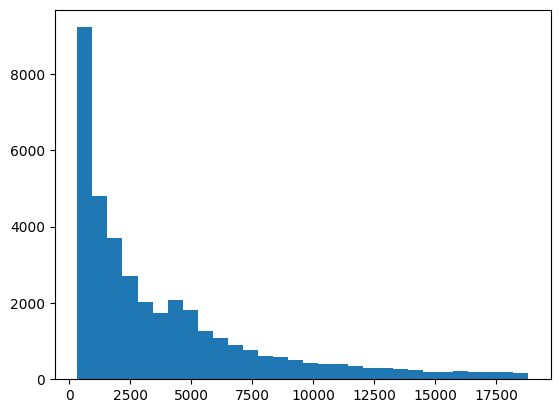

In [184]:
#e incredibil de skewed si afecteaza in special modelele lineare
print(y.skew())
import matplotlib.pyplot as plt
plt.hist(y, bins=30)
plt.show()

In [185]:
y = np.log(y)

In [186]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import cross_val_score

model = model = LGBMRegressor(
    n_estimators=3000,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
cross_val_score(model, X, y, cv=5, scoring='neg_mean_absolute_error')

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001931 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1763
[LightGBM] [Info] Number of data points in the train set: 30206, number of used features: 11
[LightGBM] [Info] Start training from score 7.789677
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001499 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1766
[LightGBM] [Info] Number of data points in the train set: 30206, number of used features: 11
[LightGBM] [Info] Start training from score 7.794282
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001538 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1765
[LightGBM] [Info] Number of data points in the train set: 30206, number of used features: 11
[LightGBM] [Info] Start tra

array([-0.06085135, -0.06193632, -0.06175208, -0.06084777, -0.06057764])

In [187]:
model.fit(X, y)
y_final = model.predict(X_final)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002480 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1777
[LightGBM] [Info] Number of data points in the train set: 37758, number of used features: 11
[LightGBM] [Info] Start training from score 7.790624


In [188]:
df_preds = pd.DataFrame({
    "subtaskID": 4,
    "datapointID": df_test.SampleID,
    "answer": np.exp(y_final)
})

df_preds.head()

,subtaskID,datapointID,answer
0,4,1389,541.714519
1,4,50053,2302.909195
2,4,41646,1226.989058
3,4,42378,1284.611440
4,4,17245,9348.683949


In [189]:
submission = pd.concat([subtasks, df_preds])
submission

,subtaskID,datapointID,answer
0,1,1389,Light
1,1,50053,Medium
2,1,41646,Light
3,1,42378,Light
4,1,17245,Heavy
...,...,...,...
16177,4,29578,785.225556
16178,4,12565,4884.455703
16179,4,24787,12568.917127
16180,4,1333,3289.117475


In [190]:
submission.to_csv("submission.csv", index=False)